# Transporter Networks: pick it up, put it there

Given **one image**, we will train two small neural networks:

1. **Attention** finds the object to pick.
2. **Transport** compares a crop around that object with the whole scene and finds the place location.

We skip rotation. Every point is `(x, y)`: `x` moves right and `y` moves down. The model scores every pixel, so its answer is a **heatmap**, not just two regressed numbers.

In [ ]:
!wget -q https://raw.githubusercontent.com/dignakov/ai-intro-workshop-1/refs/heads/main/transporter_utils.py -O transporter_utils.py


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.patches import Circle
from torch.utils.data import Subset

from transporter_utils import (
    AttentionNet, RealDataset, ToyDataset, TransporterNet,
    count_parameters, crop_square, evaluate_pipeline, get_device,
    load_checkpoint, make_batch, predict, render_toy_goal,
    save_checkpoint, seed_everything, suggest_crop_size, to_original_coordinates,
    train_attention, train_transporter,
)

seed_everything(0)
device = get_device()
IMAGE_SIZE = 320
CROP_SIZE = 160
BATCH_SIZE = 4
print('Using:', device)

Using: cuda


In [2]:
def show_sample(ax, sample, title=''):
    ax.imshow(sample.image)
    ax.scatter(*sample.pick, c='lime', s=70, edgecolors='black', label='pick')
    ax.scatter(*sample.place, c='magenta', s=70, edgecolors='black', label='place')
    ax.add_patch(Circle(sample.pick, sample.pick_radius, fill=False,
                        edgecolor='lime', linewidth=1.5))
    arrow_color = 'black' if sample.metadata.get('kind') == 'toy' else 'white'
    ax.annotate('', xy=sample.place, xytext=sample.pick,
                arrowprops={'arrowstyle': '->', 'color': arrow_color,
                            'lw': 2, 'linestyle': '--'})
    ax.set_title(title)
    ax.axis('off')


def show_prediction(sample, prediction, title=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    show_sample(axes[0], sample, title or 'Ground truth')
    axes[0].scatter(*prediction.pick, marker='x', s=120, c='cyan', label='predicted pick')
    axes[0].scatter(*prediction.place, marker='x', s=120, c='yellow', label='predicted place')
    axes[0].legend(loc='lower center', fontsize=8)
    axes[1].imshow(prediction.pick_heatmap, cmap='magma')
    axes[1].set_title('Predicted pick heatmap')
    axes[2].imshow(prediction.place_heatmap, cmap='magma')
    axes[2].set_title('Predicted place heatmap')
    for ax in axes[1:]:
        ax.axis('off')
    plt.show()

## 1. A complete toy dataset

Each example contains a red square, a blue square, a pick point, and a place point. The correct action moves the red square to the **left of the blue square with their top corners aligned**. Sizes and positions vary. The goal image is a picture of the answer; it is **not** a model input.

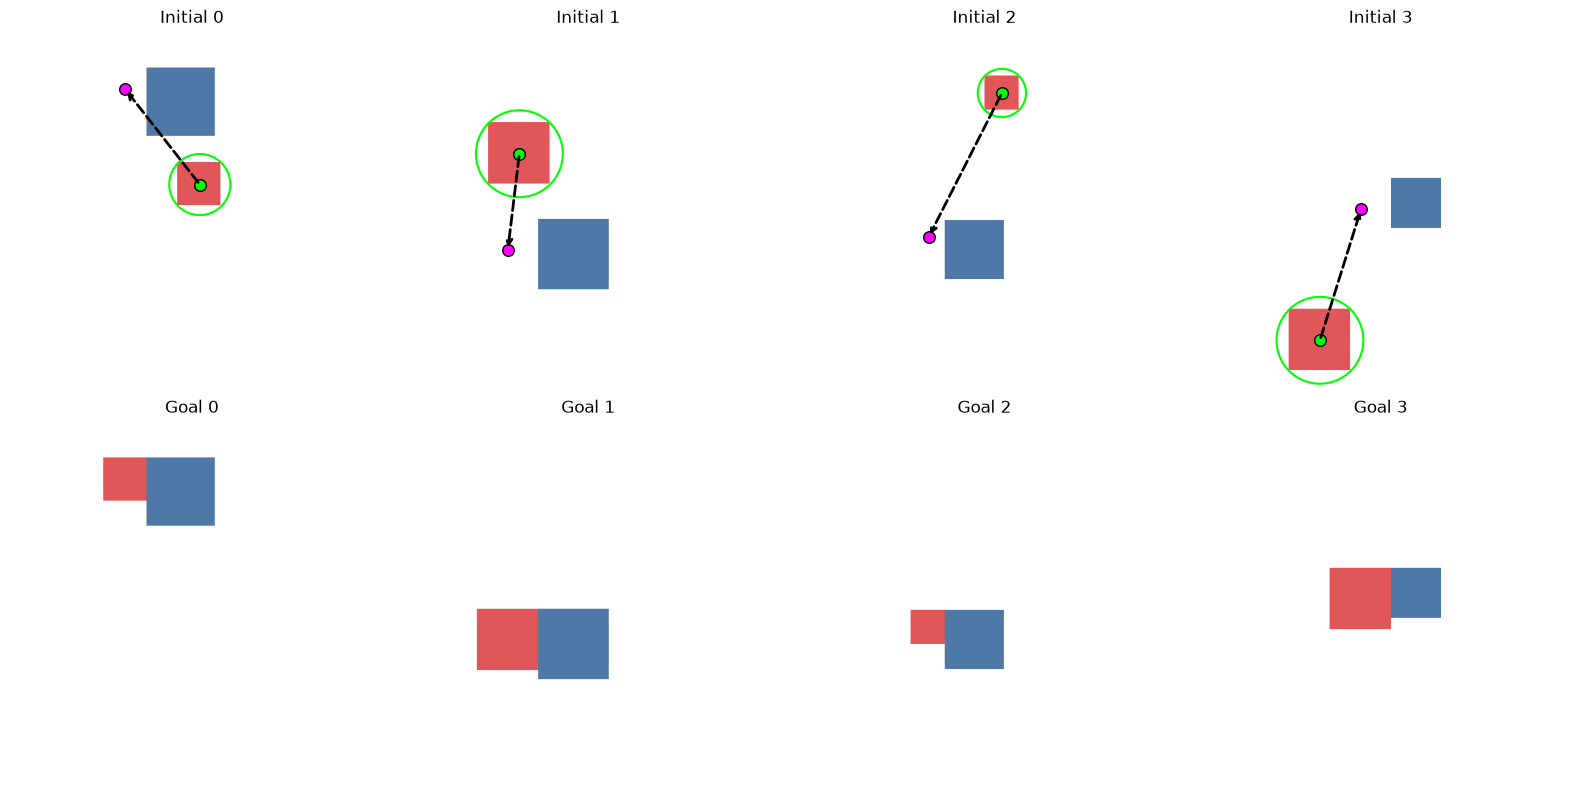

In [3]:
toy_train = ToyDataset(100, image_size=IMAGE_SIZE, augment=True, seed=10)
toy_test = ToyDataset(20, image_size=IMAGE_SIZE, seed=20)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for column in range(4):
    sample = toy_test[column]
    show_sample(axes[0, column], sample, f'Initial {column}')
    axes[1, column].imshow(render_toy_goal(sample))
    axes[1, column].set_title(f'Goal {column}')
    axes[1, column].axis('off')
plt.tight_layout()
plt.show()

### Points become probability maps

A small Gaussian marks the correct pixel. Training uses cross-entropy over all `320 × 320 = 102,400` pixels. The transport query is a `160 × 160` crop centered on the pick; padding handles objects near an edge. The crop size is chosen from the labeled object radii and remains fixed at inference.

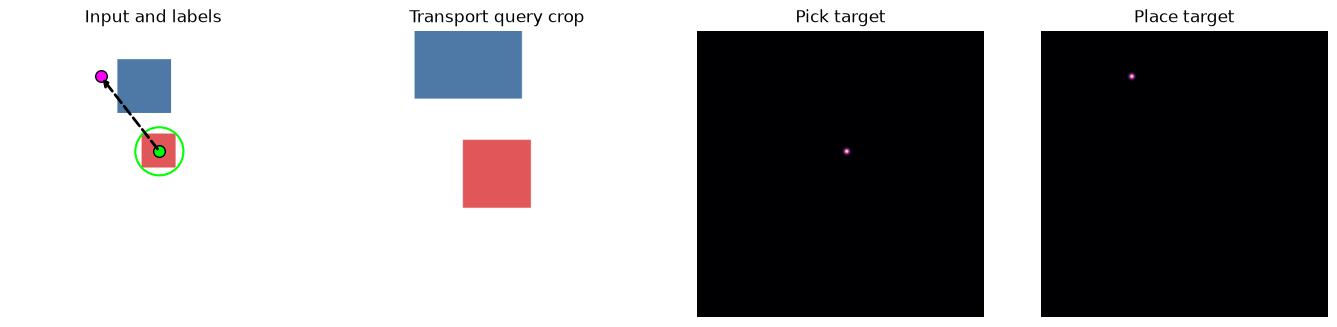

{'image': (1, 3, 320, 320), 'query': (1, 3, 160, 160), 'pick_target': (1, 320, 320), 'place_target': (1, 320, 320), 'pick_xy': (1, 2), 'place_xy': (1, 2)}


In [4]:
sample = toy_test[0]
batch = make_batch([sample], crop_size=CROP_SIZE)
query = crop_square(sample.image, sample.pick, CROP_SIZE)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
show_sample(axes[0], sample, 'Input and labels')
axes[1].imshow(query)
axes[1].set_title('Transport query crop')
axes[2].imshow(batch['pick_target'][0], cmap='magma')
axes[2].set_title('Pick target')
axes[3].imshow(batch['place_target'][0], cmap='magma')
axes[3].set_title('Place target')
for ax in axes[1:]:
    ax.axis('off')
plt.show()
print({key: tuple(value.shape) for key, value in batch.items()})

## 2. Train the two stages

We first train each stage with its true label. Transport receives the **ground-truth pick crop** during training, so bad early attention predictions cannot interfere with place learning. At inference, the predicted pick will choose the crop.

In [5]:
attention = AttentionNet()
transporter = TransporterNet()
print(f'Attention parameters:   {count_parameters(attention):,}')
print(f'Transporter parameters: {count_parameters(transporter):,}')

Attention parameters:   118,993
Transporter parameters: 238,272


In [6]:
attention_history = train_attention(
    attention, toy_train, toy_test, device,
    epochs=10, batch_size=BATCH_SIZE, crop_size=CROP_SIZE,
    learning_rate=1e-3, report_every=2,
)

attention epoch   2 | loss 5.3481 | val pick error 0.76px


attention epoch   4 | loss 4.8076 | val pick error 0.59px


attention epoch   6 | loss 4.4029 | val pick error 0.91px


attention epoch   8 | loss 4.3732 | val pick error 1.26px


attention epoch  10 | loss 4.3541 | val pick error 0.72px


In [7]:
transport_history = train_transporter(
    transporter, toy_train, toy_test, device,
    epochs=15, batch_size=BATCH_SIZE, crop_size=CROP_SIZE,
    learning_rate=1e-3, report_every=3,
)

transport epoch   3 | loss 5.1420 | val place error 4.46px


transport epoch   6 | loss 4.7494 | val place error 0.38px


transport epoch   9 | loss 4.4996 | val place error 3.17px


transport epoch  12 | loss 4.7485 | val place error 0.57px


transport epoch  15 | loss 4.7310 | val place error 0.48px


## 3. Put them together

The attention heatmap selects a pick pixel. We crop there and pass that crop to the transporter, which produces the place heatmap. The test examples were generated from a different seed and are never used for gradient updates.

Mean unseen toy error: {'pick_error': 0.7213448945538943, 'place_error': 0.788631471353303}


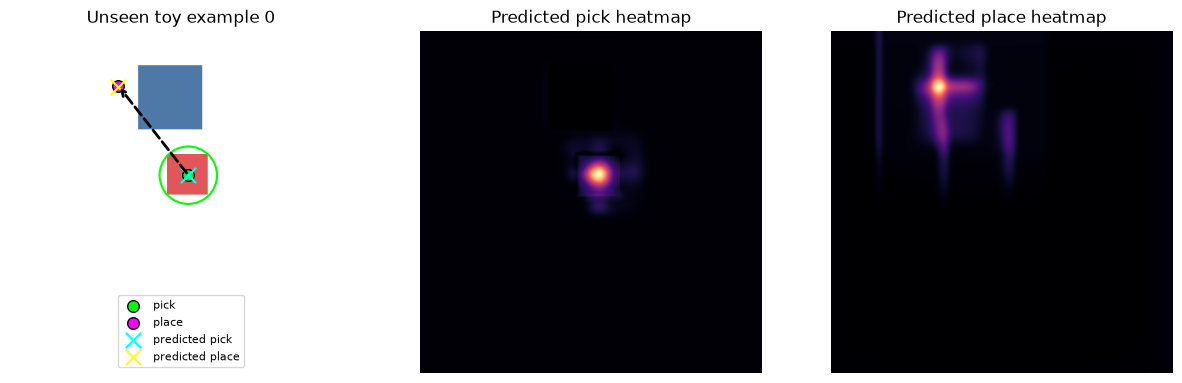

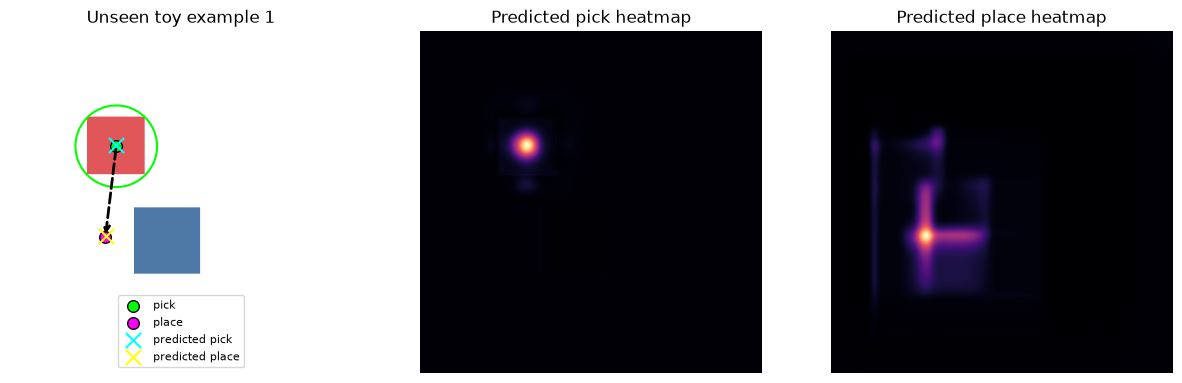

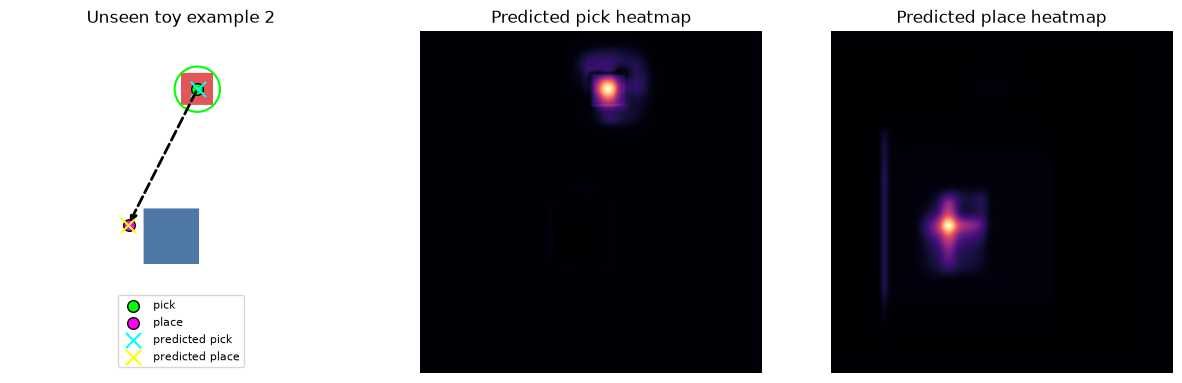

In [8]:
print('Mean unseen toy error:', evaluate_pipeline(
    attention, transporter, toy_test, device, CROP_SIZE
))
for index in range(3):
    sample = toy_test[index]
    prediction = predict(attention, transporter, sample, device, CROP_SIZE)
    show_prediction(sample, prediction, f'Unseen toy example {index}')

## 4. Real phone photos

The same sample format works for the app data. Photos are resized without distortion and reflect-padded onto a `320 × 320` canvas. Pick, place, and radius receive exactly the same transform.

This task is **move the wallet onto the box**, which is different from the toy relation. Six photos are enough to test the pipeline, not to demonstrate generalization. Collect more photos and keep a genuinely held-out test set for a real workshop.

In [ ]:
data_path = Path('../interns_crap_demo/dataset')
real_all = RealDataset(data_path, image_size=IMAGE_SIZE, augment=False)
suggested_crop = suggest_crop_size(real_all)
print(f'Radius-based crop suggestion: {suggested_crop} × {suggested_crop}; using {CROP_SIZE} × {CROP_SIZE}')
if CROP_SIZE < suggested_crop:
    print('Warning: increase CROP_SIZE so the largest augmented object fits.')
real_augmented = RealDataset(data_path, image_size=IMAGE_SIZE, augment=True, seed=30)
real_train = Subset(real_augmented, [0, 1, 2, 3])
real_test = Subset(real_all, [4, 5])

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for index, ax in enumerate(axes.flat):
    show_sample(ax, real_all[index], f'{index}: {real_all.records[index]["sample_id"]}')
plt.tight_layout()
plt.show()

### Augmentation happens on the fly

Small rotations, translations, scale changes, flips, brightness, and contrast make each training visit a little different. The points move with the image. Flips are enabled here because ‘on the box’ has no left/right meaning; they remain disabled for the toy task.

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
show_sample(axes[0], real_all[0], 'Canonical original')
for index in range(1, 4):
    show_sample(axes[index], real_augmented[0], f'Augmented view {index}')
plt.tight_layout()
plt.show()

In [ ]:
real_attention = AttentionNet()
real_transporter = TransporterNet()
train_attention(
    real_attention, real_train, real_test, device,
    epochs=8, batch_size=BATCH_SIZE, crop_size=CROP_SIZE,
    learning_rate=1e-3, report_every=2,
)
train_transporter(
    real_transporter, real_train, real_test, device,
    epochs=8, batch_size=BATCH_SIZE, crop_size=CROP_SIZE,
    learning_rate=1e-3, report_every=2,
)

In [ ]:
print('Two held-out photos:', evaluate_pipeline(
    real_attention, real_transporter, real_test, device, CROP_SIZE
))
for index in [0, 4, 5]:
    sample = real_all[index]
    prediction = predict(real_attention, real_transporter, sample, device, CROP_SIZE)
    split = 'train' if index < 4 else 'held-out'
    show_prediction(sample, prediction, f'Real {split} example {index}')
    print('Prediction in original photo coordinates:',
          to_original_coordinates(sample, prediction.pick),
          to_original_coordinates(sample, prediction.place))

## 5. Save and reload

The checkpoint contains both state dictionaries and the image/crop configuration. For a workshop with more data, save the checkpoint with the best held-out error—not merely the final epoch.

In [13]:
checkpoint_path = Path('checkpoints/workshop_demo.pt')
save_checkpoint(real_attention, real_transporter, checkpoint_path, IMAGE_SIZE, CROP_SIZE)
loaded_attention, loaded_transporter, config = load_checkpoint(checkpoint_path, device)
sample = real_all[0]
original = predict(real_attention, real_transporter, sample, device, CROP_SIZE)
reloaded = predict(loaded_attention, loaded_transporter, sample, device, CROP_SIZE)
assert original.pick == reloaded.pick and original.place == reloaded.place
print('Reloaded predictions match. Config:', config)

Reloaded predictions match. Config: {'image_size': 320, 'crop_size': 160}


## Try it

- Change the toy rule from ‘left of blue’ to ‘on top of blue’ or ‘below blue’. Which labels must change?
- Increase Gaussian `sigma` in `make_batch`. How does that change the targets?
- Collect 20–30 photos with a fixed phone position, then add to them gradually. Which variations break the model first?
- Compare training error with held-out error. A tiny training error alone does not mean the robot learned the task.

These are image coordinates, not calibrated robot commands. A physical robot would additionally need camera calibration, a safe grasp height, collision checks, and a controller.